# EDA

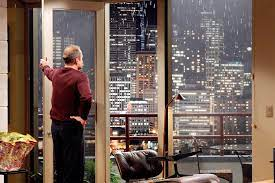

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()
pd.set_option("display.float_format", lambda x: "%.3f" % x)

## Kunde und Fragestellung

**Kunde:** Charles Christensen, Verkäufer. Investiert mit dem Ziel hoher Rendite, überlegt zu renovieren, fragt nach dem richtigen Viertel und dem richtigen Zeitpunkt.

**Fragestellung:** Wie holt Charles beim Verkauf am meisten raus? Lohnt sich eine Renovierung, welche Lage zahlt sich aus, und wann verkauft er am besten?

## Hypothesen

| # | Hypothese | So messe ich es | Spalten |
|---|---|---|---|
| H1 | Renovierte Häuser verkaufen sich besser als unrenovierte. | Median-Preis pro m² renovierter und nicht renovierter Häuser, bei vergleichbarer Größe | `yr_renovated`, `price`, `sqft_living` |
| H2 | Die Lage entscheidet über den Quadratmeterpreis. | Median-Preis pro m² je PLZ und nach Entfernung zum Zentrum (geografische Erkenntnis) | `zipcode`, `lat`, `long` |
| H3 | Die Verkaufspreise im Frühjahr sind besser als im Herbst. | Median-Preis pro m² nach Verkaufsmonat und Jahreszeit | `date`, `price` |

## Annahmen

- **Preis pro m²:** Die Daten sind in Quadratfuß. Für ein deutsches Publikum rechne ich in m² um (1 sqft = 0,0929 m²).
- **Vergleich über den Median:** Hauspreise sind rechtsschief, wenige sehr teure Häuser würden den Durchschnitt verzerren.
- **Zentrum:** Downtown Seattle (Breite 47,61, Länge -122,33).
- **Renoviert:** `yr_renovated` größer als 0. Fehlende Werte: Entscheidung in der Bereinigung.
- **Jahreszeiten:** Frühjahr = März bis Mai, Herbst = September bis November.
- **Zeitraum:** Die Daten decken nur Mai 2014 bis Mai 2015 ab. Aussagen zum Timing gelten für dieses eine Jahr.

## 1. Daten laden

In [2]:
df = pd.read_csv("data/king_county.csv", parse_dates=["date"])
df.shape

(21597, 22)

## 2. Daten verstehen

Überblick: Datentypen, Kennzahlen, fehlende Werte, Duplikate.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   sale_id        21597 non-null  int64         
 1   date           21597 non-null  datetime64[us]
 2   price          21597 non-null  float64       
 3   id             21597 non-null  int64         
 4   bedrooms       21597 non-null  float64       
 5   bathrooms      21597 non-null  float64       
 6   sqft_living    21597 non-null  float64       
 7   sqft_lot       21597 non-null  float64       
 8   floors         21597 non-null  float64       
 9   waterfront     19206 non-null  float64       
 10  view           21534 non-null  float64       
 11  condition      21597 non-null  int64         
 12  grade          21597 non-null  int64         
 13  sqft_above     21597 non-null  float64       
 14  sqft_basement  21145 non-null  float64       
 15  yr_built       21597 non-null 

In [4]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
sale_id,21597.000,10799.000,1.000,5400.000,10799.000,16198.000,21597.000,6234.661
date,21597,2014-10-29 04:20:38.171968,2014-05-02 00:00:00,2014-07-22 00:00:00,2014-10-16 00:00:00,2015-02-17 00:00:00,2015-05-27 00:00:00,NaN
price,21597.000,540296.574,78000.000,322000.000,450000.000,645000.000,7700000.000,367368.140
id,21597.000,4580474287.771,1000102.000,2123049175.000,3904930410.000,7308900490.000,9900000190.000,2876735715.748
bedrooms,21597.000,3.373,1.000,3.000,3.000,4.000,33.000,0.926
bathrooms,21597.000,2.116,0.500,1.750,2.250,2.500,8.000,0.769
sqft_living,21597.000,2080.322,370.000,1430.000,1910.000,2550.000,13540.000,918.106
sqft_lot,21597.000,15099.409,520.000,5040.000,7618.000,10685.000,1651359.000,41412.637
floors,21597.000,1.494,1.000,1.000,1.500,2.000,3.500,0.540
waterfront,19206.000,0.008,0.000,0.000,0.000,0.000,1.000,0.087


In [5]:
df.isna().sum()

sale_id             0
date                0
price               0
id                  0
bedrooms            0
bathrooms           0
sqft_living         0
sqft_lot            0
floors              0
waterfront       2391
view               63
condition           0
grade               0
sqft_above          0
sqft_basement     452
yr_built            0
yr_renovated     3848
zipcode             0
lat                 0
long                0
sqft_living15       0
sqft_lot15          0
dtype: int64

## 3. Daten bereinigen

Jede Entscheidung mit Begründung und Anzahl betroffener Zeilen festhalten.

In [6]:
import numpy as np

zeilen_vorher = len(df)

### 3.1 Renovierungsjahr: Einheitenfehler

Die Werte stehen als 19340, 20140 usw. in den Daten. Das sind Jahreszahlen mal 10. Ich teile durch 10. `0` bedeutet „nie renoviert“, fehlende Werte bleiben fehlend.

In [7]:
print("vorher:", df.yr_renovated[df.yr_renovated > 0].min(), "bis", df.yr_renovated.max())
df["yr_renovated"] = df["yr_renovated"] / 10
print("nachher:", df.yr_renovated[df.yr_renovated > 0].min(), "bis", df.yr_renovated.max())

# Plausibilität: keine Renovierung vor dem Baujahr
print("Renoviert vor Baujahr:", ((df.yr_renovated > 0) & (df.yr_renovated < df.yr_built)).sum())

vorher: 19340.0 bis 20150.0
nachher: 1934.0 bis 2015.0
Renoviert vor Baujahr: 0


### 3.2 Renovierungsjahr: fehlende Werte

Bei rund 18 % der Verkäufe fehlt das Renovierungsjahr. Mit „nicht renoviert“ aufzufüllen wäre geraten und könnte H1 verfälschen. Deshalb bekommt jede Zeile eine eigene Kategorie: ja, nein oder unbekannt. Für H1 lasse ich „unbekannt“ weg, für H2 und H3 bleiben alle Zeilen drin.

Dazu eine Schärfung für Charles: Interessant ist vor allem eine Renovierung kurz vor dem Verkauf. `renoviert_10j` heißt: renoviert in den letzten 10 Jahren vor dem Verkauf.

In [8]:
df["renoviert"] = np.select(
    [df.yr_renovated > 0, df.yr_renovated == 0], ["ja", "nein"], default="unbekannt"
)
jahre_seit_renovierung = df.date.dt.year - df.yr_renovated
df["renoviert_10j"] = np.select(
    [(df.yr_renovated > 0) & (jahre_seit_renovierung <= 10), df.yr_renovated.notna()],
    ["ja", "nein"],
    default="unbekannt",
)
df[["renoviert", "renoviert_10j"]].apply(pd.Series.value_counts)

,renoviert,renoviert_10j
nein,17005,17466
unbekannt,3848,3848
ja,744,283


### 3.3 Ausreißer: 33 Schlafzimmer

Ein Haus hat laut Daten 33 Schlafzimmer. Das ist vermutlich ein Tippfehler für 3. Für meine Hypothesen spielt die Zimmerzahl keine Rolle, deshalb lösche ich die eine Zeile, statt zu raten.

In [9]:
print(df.loc[df.bedrooms == 33, ["price", "bedrooms", "bathrooms", "sqft_living"]])
df = df[df.bedrooms != 33]

           price  bedrooms  bathrooms  sqft_living
15856 640000.000    33.000      1.750     1620.000


### 3.4 Was ich bewusst nicht ändere

- **Mehrfach verkaufte Häuser (177 Verkäufe):** Jeder Verkauf ist ein echter Marktpreis. Gerade für das Timing (H3) zählt jeder einzelne.
- **Sehr teure Häuser (45 über 3 Mio. $):** bleiben drin. Ich vergleiche über den Median, der ist robust gegen Ausreißer.
- **Wasserlage, Aussicht, Kellerfläche mit Lücken:** für meine drei Hypothesen nicht nötig.
- **Duplikate:** Es gibt keine doppelten Zeilen.

In [10]:
print("Doppelte Zeilen:", df.duplicated().sum())
print("Häuser mit mehreren Verkäufen:", df.id.duplicated().sum())
print("Verkäufe über 3 Mio. $:", (df.price > 3_000_000).sum())

Doppelte Zeilen: 0
Häuser mit mehreren Verkäufen: 177
Verkäufe über 3 Mio. $: 45


### 3.5 Neue Spalten für die Hypothesen

- `preis_m2`: Preis pro m² Wohnfläche (H1, H2). 1 sqft = 0,0929 m².
- `entfernung_km`: Luftlinie zum Zentrum von Seattle (H2).
- `monat` und `jahreszeit` (H3).

In [11]:
df["wohnflaeche_m2"] = df.sqft_living * 0.0929
df["preis_m2"] = df.price / df.wohnflaeche_m2

# Luftlinie zu Downtown Seattle (Haversine-Formel)
lat0, lon0 = np.radians(47.6062), np.radians(-122.3321)
lat, lon = np.radians(df.lat), np.radians(df.long)
a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat) * np.sin((lon - lon0) / 2) ** 2
df["entfernung_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

df["monat"] = df.date.dt.month
df["jahreszeit"] = df.monat.map(
    {12: "Winter", 1: "Winter", 2: "Winter", 3: "Frühjahr", 4: "Frühjahr", 5: "Frühjahr",
     6: "Sommer", 7: "Sommer", 8: "Sommer", 9: "Herbst", 10: "Herbst", 11: "Herbst"}
)
df[["preis_m2", "entfernung_km", "monat", "jahreszeit"]].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
preis_m2,21596.000,NaN,NaN,NaN,2843.243,1184.058,942.823,1962.235,2633.227,3426.570,8720.548
entfernung_km,21596.000,NaN,NaN,NaN,18.452,10.637,0.983,9.783,16.506,25.261,77.094
monat,21596.000,NaN,NaN,NaN,6.574,3.115,1.000,4.000,6.000,9.000,12.000
jahreszeit,21596,4,Frühjahr,6518,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.6 Bilanz

In [12]:
print(f"Zeilen vorher: {zeilen_vorher}, nachher: {len(df)}, entfernt: {zeilen_vorher - len(df)}")

Zeilen vorher: 21597, nachher: 21596, entfernt: 1


## 4. Hypothesen prüfen

### H1: Renovierung

**H1: Renovierte Häuser verkaufen sich besser als unrenovierte.**

Ich vergleiche den Preis pro m², damit größere Häuser nicht automatisch „besser“ abschneiden. Häuser mit unbekanntem Renovierungsstatus lasse ich hier weg.

In [13]:
import seaborn as sns

h1 = df[df.renoviert != "unbekannt"]
h1.groupby("renoviert").agg(
    verkaeufe=("price", "size"),
    preis_median=("price", "median"),
    preis_m2_median=("preis_m2", "median"),
    wohnflaeche_m2=("wohnflaeche_m2", "median"),
    baujahr=("yr_built", "median"),
    entfernung_km=("entfernung_km", "median"),
).round(0)

,verkaeufe,preis_median,preis_m2_median,wohnflaeche_m2,baujahr,entfernung_km
renoviert,,,,,,
ja,744,607502.000,3246.000,204.000,1942.000,10.000
nein,17004,448000.000,2613.000,177.000,1977.000,17.000


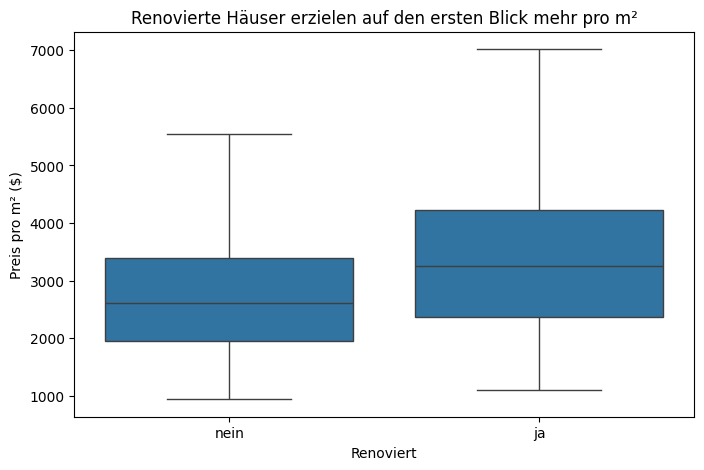

In [14]:
fig, ax = plt.subplots()
sns.boxplot(data=h1, x="renoviert", y="preis_m2", order=["nein", "ja"], showfliers=False, ax=ax)
ax.set(title="Renovierte Häuser erzielen auf den ersten Blick mehr pro m²",
       xlabel="Renoviert", ylabel="Preis pro m² ($)")
plt.show()

Auf den ersten Blick ist der Unterschied groß: Renovierte Häuser erzielen im Median rund 3.250 $ pro m², nicht renovierte rund 2.610 $. Das sind gut 24 % mehr.

Die Tabelle zeigt aber auch: Renovierte Häuser sind deutlich älter (Baujahr im Median 1942 statt 1977) und liegen näher am Zentrum (10 statt 17 km). Ein Teil des Aufschlags könnte also an der Lage liegen und nicht an der Renovierung.

### Fairer Vergleich 1: ähnliche Wohnfläche

In [15]:
h1 = h1.assign(groesse=pd.qcut(h1.wohnflaeche_m2, 5, labels=["sehr klein", "klein", "mittel", "groß", "sehr groß"]))
nach_groesse = h1.pivot_table(index="groesse", columns="renoviert", values="preis_m2", aggfunc="median", observed=True)
nach_groesse["aufschlag_%"] = (nach_groesse["ja"] / nach_groesse["nein"] - 1) * 100
nach_groesse.round(1)

renoviert,ja,nein,aufschlag_%
groesse,,,
sehr klein,3439.700,3149.700,9.200
klein,3231.000,2728.400,18.400
mittel,3125.200,2373.200,31.700
groß,3158.200,2375.800,32.900
sehr groß,3545.500,2574.500,37.700


In jeder Größenklasse liegen renovierte Häuser vorne, zwischen rund 9 % (sehr kleine Häuser) und 38 % (sehr große Häuser). Die Größe erklärt den Unterschied also nicht.

### Fairer Vergleich 2: gleiches Viertel (PLZ)

In [16]:
def aufschlag_je_plz(daten, spalte, mindestens=5):
    """Median-Aufschlag pro m² von 'ja' gegenüber 'nein' innerhalb jeder PLZ."""
    t = daten.groupby(["zipcode", spalte]).preis_m2.agg(["median", "size"]).unstack()
    t = t[t["size"]["ja"] >= mindestens]
    aufschlag = (t["median"]["ja"] / t["median"]["nein"] - 1) * 100
    print(f"PLZ im Vergleich: {len(aufschlag)}, renoviert teurer in {(aufschlag > 0).sum()}")
    print(f"Median-Aufschlag innerhalb der PLZ: {aufschlag.median():.1f} %")
    return aufschlag

aufschlag_alle = aufschlag_je_plz(h1, "renoviert")

PLZ im Vergleich: 47, renoviert teurer in 29
Median-Aufschlag innerhalb der PLZ: 3.4 %


Vergleicht man nur Häuser im selben Viertel, schrumpft der Aufschlag deutlich: auf rund 3 % im Median. In 29 von 47 Vierteln liegen renovierte Häuser vorne, in 18 nicht. Der große Unterschied von oben kommt also vor allem daher, dass renovierte Häuser häufiger in teuren, zentralen Lagen stehen.

### Schärfung: frisch renoviert (letzte 10 Jahre vor dem Verkauf)

In [17]:
h1_10 = df[df.renoviert_10j != "unbekannt"]
print(h1_10.groupby("renoviert_10j").preis_m2.agg(["size", "median"]).round(0))
aufschlag_10j = aufschlag_je_plz(h1_10, "renoviert_10j")

                size   median
renoviert_10j                
ja               283 3414.000
nein           17465 2624.000
PLZ im Vergleich: 24, renoviert teurer in 18
Median-Aufschlag innerhalb der PLZ: 6.8 %


Bei Häusern, die in den 10 Jahren vor dem Verkauf renoviert wurden, ist der Aufschlag im selben Viertel etwa doppelt so hoch: rund 7 % im Median, in 18 von 24 Vierteln positiv. Einschränkung: Das sind nur 283 Verkäufe.

### Ergebnis H1

- **Teilweise bestätigt.** Renovierte Häuser erzielen mehr pro m², aber weit weniger, als der erste Blick vermuten lässt.
- Der rohe Unterschied (+24 %) ist größtenteils ein Lageeffekt. Im selben Viertel bleiben rund **+3 %**, bei frischer Renovierung rund **+7 %**.
- **Für Charles heißt das:** Eine Renovierung kurz vor dem Verkauf bringt einen messbaren, aber moderaten Aufschlag. Ob sie sich lohnt, hängt an den Kosten. Die Lage hat den größeren Hebel, siehe H2.
- Einschränkungen: Renovierungskosten sind nicht in den Daten, und bei 18 % der Verkäufe fehlt das Renovierungsjahr.

### H2: Lage

**H2: Die Lage entscheidet über den Quadratmeterpreis.**

Ich messe die Lage auf zwei Arten: als Entfernung zum Zentrum von Seattle und als Postleitzahl (Viertel).

In [18]:
print("Rangkorrelation Entfernung zu Preis pro m²:", round(df.entfernung_km.corr(df.preis_m2, method="spearman"), 2))

zonen = pd.cut(df.entfernung_km, [0, 5, 10, 15, 20, 30, 80],
               labels=["bis 5 km", "5–10 km", "10–15 km", "15–20 km", "20–30 km", "über 30 km"])
nach_entfernung = df.groupby(zonen, observed=True).agg(
    verkaeufe=("price", "size"), preis_m2_median=("preis_m2", "median"), preis_median=("price", "median")
)
nach_entfernung.round(0)

Rangkorrelation Entfernung zu Preis pro m²: -0.62


,verkaeufe,preis_m2_median,preis_median
entfernung_km,,,
bis 5 km,1343,3977.000,638000.000
5–10 km,4274,3646.000,536750.000
10–15 km,3799,2942.000,466750.000
15–20 km,3962,2562.000,449000.000
20–30 km,4455,2350.000,458000.000
über 30 km,3763,1805.000,309780.000


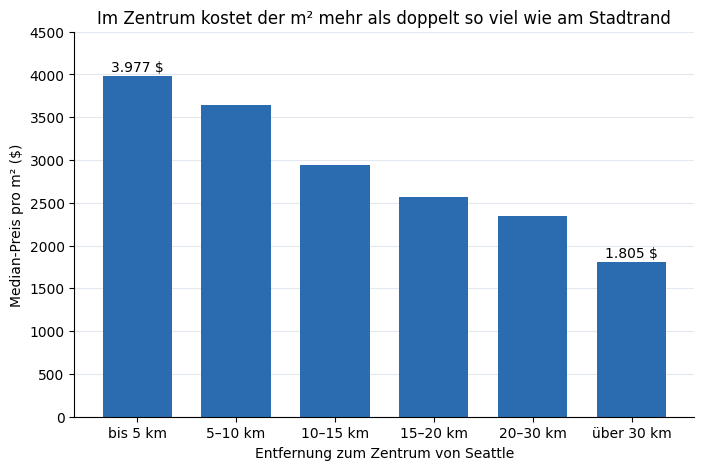

In [19]:
fig, ax = plt.subplots()
ax.bar(nach_entfernung.index.astype(str), nach_entfernung.preis_m2_median, color="#2b6cb0", width=0.7)
for i in [0, len(nach_entfernung) - 1]:
    wert = nach_entfernung.preis_m2_median.iloc[i]
    ax.text(i, wert + 60, f"{wert:,.0f} $".replace(",", "."), ha="center")
ax.set(title="Im Zentrum kostet der m² mehr als doppelt so viel wie am Stadtrand",
       xlabel="Entfernung zum Zentrum von Seattle", ylabel="Median-Preis pro m² ($)", ylim=(0, 4500))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e2e8f0"); ax.set_axisbelow(True)
plt.show()

Je näher am Zentrum, desto teurer der m², und zwar über alle Entfernungszonen hinweg. Bis 5 km kostet der m² im Median rund 3.980 $, über 30 km rund 1.800 $. Das ist mehr als das Doppelte. Die Rangkorrelation von -0,62 bestätigt einen deutlichen Zusammenhang.

### Karte: Preis pro m² in King County

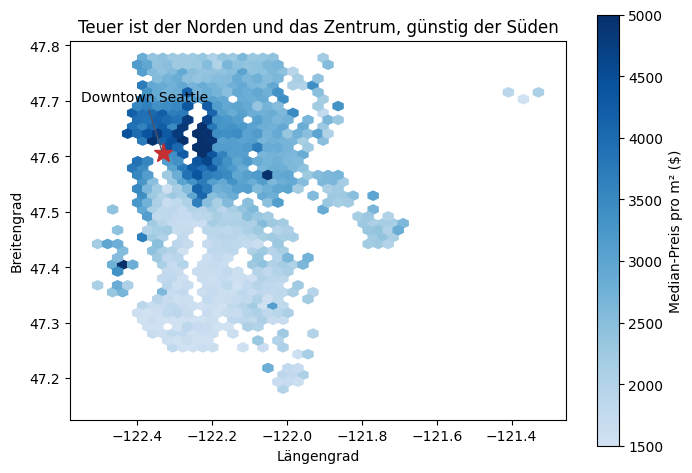

In [20]:
from matplotlib.colors import ListedColormap

# Blau ab hellem Ton statt Weiß, damit günstige Lagen sichtbar bleiben
blau = ListedColormap(plt.cm.Blues(np.linspace(0.2, 1, 256)))

fig, ax = plt.subplots(figsize=(8, 8))
hb = ax.hexbin(df.long, df.lat, C=df.preis_m2, reduce_C_function=np.median,
               gridsize=45, cmap=blau, mincnt=3, vmin=1500, vmax=5000)
ax.plot(-122.3321, 47.6062, marker="*", color="#c53030", markersize=14)
ax.annotate("Downtown Seattle", (-122.3321, 47.6062), xytext=(-122.55, 47.70),
            arrowprops=dict(arrowstyle="-", color="#4a5568"))
fig.colorbar(hb, ax=ax, label="Median-Preis pro m² ($)", shrink=0.7)
ax.set(title="Teuer ist der Norden und das Zentrum, günstig der Süden",
       xlabel="Längengrad", ylabel="Breitengrad")
ax.set_aspect(1 / np.cos(np.radians(47.5)))
plt.show()

**Interaktive Karte mit Stadtplan.** Jeder Punkt ist ein Verkauf. Die Zelle speichert die Karte als eigene Datei `bilder/karte_preis_m2.html`. Das Notebook zeigt sie nicht an, um die Datei klein zu halten.

In [21]:
import os
import plotly.express as px

os.makedirs("bilder", exist_ok=True)
karte = df.assign(
    preis_m2_karte=df.preis_m2.clip(1500, 5000),
    preis_fmt=df.price.map(lambda x: f"{x:,.0f} $".replace(",", ".")),
    preis_m2_fmt=df.preis_m2.map(lambda x: f"{x:,.0f} $".replace(",", ".")),
    flaeche_fmt=df.wohnflaeche_m2.round(0).astype(int).astype(str) + " m²",
)
fig = px.scatter_map(
    karte, lat="lat", lon="long", color="preis_m2_karte",
    color_continuous_scale=["#c6dbef", "#6baed6", "#2171b5", "#08306b"],
    range_color=(1500, 5000), zoom=9.2, center={"lat": 47.50, "lon": -122.18},
    opacity=0.7, map_style="carto-positron", height=750,
    hover_data={"preis_m2_karte": False, "lat": False, "long": False, "zipcode": True,
                "preis_fmt": True, "preis_m2_fmt": True, "flaeche_fmt": True, "yr_built": True, "renoviert": True},
    labels={"zipcode": "PLZ", "preis_fmt": "Preis", "preis_m2_fmt": "Preis pro m²", "flaeche_fmt": "Wohnfläche",
            "yr_built": "Baujahr", "renoviert": "Renoviert", "preis_m2_karte": "Preis pro m² ($)"},
    title="Preis pro m² in King County: teuer im Zentrum, im Norden und am Ostufer des Lake Washington",
)
fig.update_traces(marker={"size": 5})
fig.add_scattermap(lat=[47.6062], lon=[-122.3321], mode="markers+text", text=["Downtown Seattle"],
                   textposition="top right", marker={"size": 14, "color": "#c53030"},
                   hoverinfo="skip", showlegend=False)
fig.update_layout(margin={"l": 0, "r": 0, "t": 50, "b": 0}, coloraxis_colorbar={"title": "Preis pro m² ($)"})
fig.write_html("bilder/karte_preis_m2.html", include_plotlyjs="cdn")
print("gespeichert: bilder/karte_preis_m2.html")

gespeichert: bilder/karte_preis_m2.html


![Preis pro m² in King County](bilder/karte_preis_m2.png)

Das Bild ist ein Screenshot der interaktiven Karte.

**Interaktive Karte ansehen:** Die Datei `bilder/karte_preis_m2.html` im Windows-Explorer per Doppelklick öffnen. Sie läuft im Browser, mit Zoom und Details zu jedem Verkauf beim Überfahren, und braucht eine Internetverbindung für den Stadtplan. Aus VS Code oder GitHub heraus zeigt ein Klick nur den HTML-Quelltext.

Die Karte zeigt mehr als nur die Entfernung:

- Am teuersten sind das Zentrum, der Norden Seattles und die Ostseite des Lake Washington (Bellevue, Medina, Mercer Island).
- Der Süden ist bei gleicher Entfernung deutlich günstiger. In 10 bis 20 km Entfernung kostet der m² im Norden im Median rund 2.900 $, im Süden rund 2.390 $.

### Viertel im Vergleich (PLZ)

In [22]:
nach_plz = df.groupby("zipcode").agg(
    verkaeufe=("price", "size"), preis_m2_median=("preis_m2", "median"), entfernung_km=("entfernung_km", "median")
).sort_values("preis_m2_median")
print("Teuerste PLZ ist", round(nach_plz.preis_m2_median.iloc[-1] / nach_plz.preis_m2_median.iloc[0], 1),
      "mal so teuer pro m² wie die günstigste")
pd.concat([nach_plz.tail(5).iloc[::-1], nach_plz.head(5)], keys=["teuerste 5", "günstigste 5"]).round(0)

Teuerste PLZ ist 3.9 mal so teuer pro m² wie die günstigste


verkaeufe  preis_m2_median  entfernung_km
             zipcode                                           
teuerste 5   98039           50         6084.000          8.000
             98004          317         4919.000         10.000
             98109          109         4604.000          4.000
             98112          269         4567.000          4.000
             98119          184         4485.000          5.000
günstigste 5 98023          499         1560.000         33.000
             98032          125         1574.000         26.000
             98001          361         1584.000         33.000
             98002          199         1584.000         34.000
             98092          351         1606.000         36.000

### Ergebnis H2

- **Bestätigt.** Die Lage ist der stärkste Preisfaktor in den Daten. Zwischen dem teuersten Viertel (Medina, 98039) und dem günstigsten (Federal Way, 98023) liegt der Faktor 3,9 beim Preis pro m².
- Die Entfernung zum Zentrum erklärt viel, aber nicht alles. Der Norden und die Ostseite des Sees sind teurer als der Süden, auch bei gleicher Entfernung.
- **Im Vergleich zu H1:** Eine Renovierung bringt im selben Viertel rund 3 bis 7 %. Die Lage macht den Unterschied zwischen 1.800 und fast 4.000 $ pro m².
- **Für Charles heißt das:** Der größte Hebel für hohe Renditen ist die Wahl des Viertels beim Kauf, nicht die Renovierung vor dem Verkauf.

### H3: Verkaufszeitpunkt

**H3: Die Verkaufspreise im Frühjahr sind besser als im Herbst.**

Ich vergleiche den Median-Preis pro m² nach Jahreszeit und Monat. Dazu schaue ich auf die Zahl der Verkäufe, denn sie zeigt, wann die meisten Käufer am Markt sind.

In [23]:
nach_jahreszeit = df.groupby("jahreszeit").agg(
    verkaeufe=("price", "size"), preis_m2_median=("preis_m2", "median"), preis_median=("price", "median")
).loc[["Frühjahr", "Sommer", "Herbst", "Winter"]]
aufschlag = (nach_jahreszeit.preis_m2_median["Frühjahr"] / nach_jahreszeit.preis_m2_median["Herbst"] - 1) * 100
print(f"Frühjahr gegenüber Herbst: {aufschlag:+.1f} % pro m²")
nach_jahreszeit.round(0)

Frühjahr gegenüber Herbst: +4.3 % pro m²


,verkaeufe,preis_m2_median,preis_median
jahreszeit,,,
Frühjahr,6518,2720.000,465000.000
Sommer,6327,2643.000,455000.000
Herbst,5056,2607.000,443725.000
Winter,3695,2526.000,430000.000


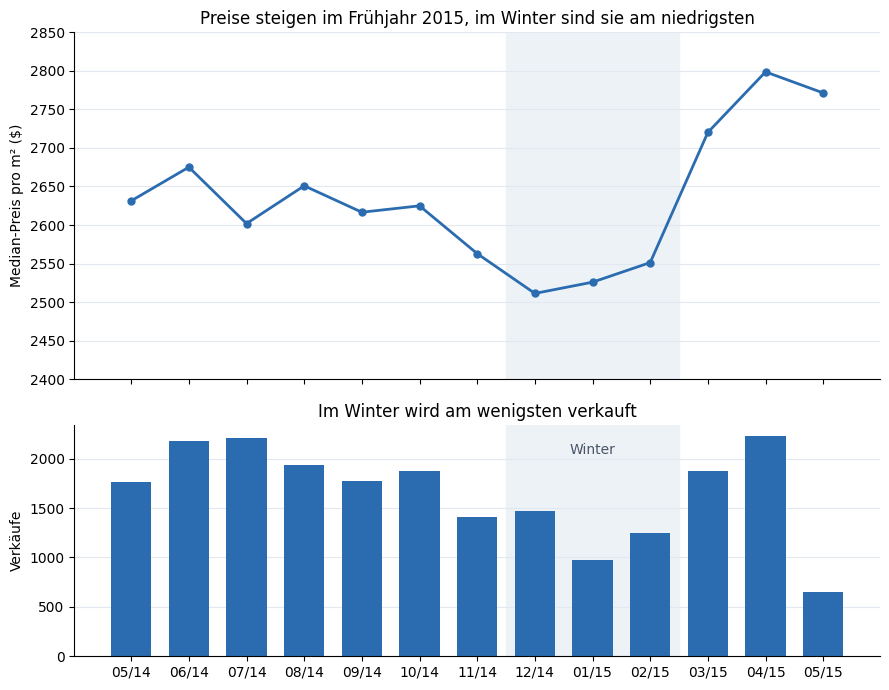

Hinweis: Mai 2014 beginnt am 02.05., Mai 2015 endet am 27.05. Der niedrige Balken im Mai 2015 ist ein unvollständiger Monat.


In [24]:
nach_monat = df.groupby(df.date.dt.to_period("M")).agg(
    verkaeufe=("price", "size"), preis_m2_median=("preis_m2", "median")
)
monate = nach_monat.index.strftime("%m/%y")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax1.plot(monate, nach_monat.preis_m2_median, color="#2b6cb0", linewidth=2, marker="o", markersize=5)
ax1.set(title="Preise steigen im Frühjahr 2015, im Winter sind sie am niedrigsten",
        ylabel="Median-Preis pro m² ($)", ylim=(2400, 2850))
ax2.bar(monate, nach_monat.verkaeufe, color="#2b6cb0", width=0.7)
ax2.set(title="Im Winter wird am wenigsten verkauft", ylabel="Verkäufe")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e2e8f0"); ax.set_axisbelow(True)
    for start, ende in [(6.5, 10.5)]:  # Winter: 12/14 bis 02/15
        ax.axvspan(start, ende - 1, color="#edf2f7", zorder=0)
ax2.text(8, nach_monat.verkaeufe.max() * 0.92, "Winter", ha="center", color="#4a5568")
plt.tight_layout()
plt.show()
print("Hinweis: Mai 2014 beginnt am 02.05., Mai 2015 endet am 27.05. Der niedrige Balken im Mai 2015 ist ein unvollständiger Monat.")

In [25]:
# Gleicher Vergleich innerhalb jedes Viertels (PLZ)
fh = df[df.jahreszeit.isin(["Frühjahr", "Herbst"])]
je_plz = fh.groupby(["zipcode", "jahreszeit"]).preis_m2.median().unstack()
aufschlag_plz = (je_plz["Frühjahr"] / je_plz["Herbst"] - 1) * 100
print(f"PLZ im Vergleich: {len(aufschlag_plz)}, Frühjahr teurer in {(aufschlag_plz > 0).sum()}")
print(f"Median-Aufschlag innerhalb der PLZ: {aufschlag_plz.median():.1f} %")

PLZ im Vergleich: 70, Frühjahr teurer in 63
Median-Aufschlag innerhalb der PLZ: 4.8 %


Auf den ersten Blick bestätigt sich die Hypothese: Im Frühjahr liegt der Preis pro m² rund 4 % über dem Herbst. Auch innerhalb desselben Viertels liegt das Frühjahr in 63 von 70 PLZ vorne.

**Aber Vorsicht:** Die Daten decken nur ein Jahr ab (Mai 2014 bis Mai 2015). Das Frühjahr besteht fast nur aus März bis Mai 2015, der Herbst aus 2014. Der Markt ist in diesem Jahr insgesamt gestiegen, das zeigt der direkte Vergleich gleicher Monate:

In [26]:
mai_14, mai_15 = nach_monat.preis_m2_median.iloc[0], nach_monat.preis_m2_median.iloc[-1]
herbst_14 = nach_jahreszeit.preis_m2_median["Herbst"]
print(f"Mai 2014: {mai_14:,.0f} $   Herbst 2014: {herbst_14:,.0f} $   Mai 2015: {mai_15:,.0f} $")
print(f"Mai 2015 gegenüber Mai 2014: {(mai_15 / mai_14 - 1) * 100:+.1f} %")
print(f"Mai 2014 gegenüber Herbst 2014: {(mai_14 / herbst_14 - 1) * 100:+.1f} %")

Mai 2014: 2,631 $   Herbst 2014: 2,607 $   Mai 2015: 2,771 $
Mai 2015 gegenüber Mai 2014: +5.3 %
Mai 2014 gegenüber Herbst 2014: +0.9 %


Mai 2014 liegt fast gleichauf mit dem Herbst 2014. Der Vorsprung des Frühjahrs 2015 kann also auch daran liegen, dass der Markt insgesamt teurer geworden ist. Mit nur einem Jahr Daten lassen sich Saison und Markttrend nicht sauber trennen.

Eindeutig ist dagegen der Winter: Dezember bis Februar haben die niedrigsten Preise und mit Abstand die wenigsten Verkäufe. Im Januar wurde nicht einmal halb so viel verkauft wie im April.

### Ergebnis H3

- **Nur bedingt bestätigt.** Das Frühjahr liegt rund 4 % über dem Herbst, aber ein Teil davon ist vermutlich der allgemeine Preisanstieg im Datenjahr.
- **Klar ist:** Der Winter ist die schlechteste Verkaufszeit, mit den niedrigsten Preisen und den wenigsten Käufern. Im Frühjahr ist die Nachfrage am höchsten.
- **Für Charles heißt das:** Nicht im Winter verkaufen. Ein Verkauf ab März trifft auf die meisten Käufer. Ob das Frühjahr auch beim Preis den Herbst schlägt, müsste man mit Daten aus mehreren Jahren prüfen.

## 5. Erkenntnisse

**1. Die Lage ist der stärkste Preisfaktor (geografisch).**
Im Zentrum von Seattle (bis 5 km) kostet der m² im Median rund 3.980 $, über 30 km entfernt rund 1.800 $. Zwischen dem teuersten Viertel (Medina) und dem günstigsten (Federal Way) liegt der Faktor 3,9. Teuer sind das Zentrum, der Norden Seattles und das Ostufer des Lake Washington, günstig ist der Süden.

**2. Der Aufschlag für Renovierung ist viel kleiner, als er aussieht.**
Roh erzielen renovierte Häuser 24 % mehr pro m². Sie liegen aber häufiger in teuren, zentralen Lagen. Im selben Viertel bleiben rund 3 %, bei Renovierung in den 10 Jahren vor dem Verkauf rund 7 %.

**3. Der Winter ist die schwächste Verkaufszeit.**
Dezember bis Februar haben die niedrigsten Preise pro m² und die wenigsten Verkäufe. Das Frühjahr liegt rund 4 % über dem Herbst. Ein Teil davon ist aber der allgemeine Preisanstieg im Datenjahr (Mai 2015 rund 5 % über Mai 2014).

**Grenzen der Analyse:** Die Daten decken nur ein Jahr ab. Renovierungskosten und Kaufpreise fehlen, eine echte Rendite lässt sich daher nicht berechnen. Bei 18 % der Verkäufe fehlt das Renovierungsjahr. Die Vergleiche zeigen Zusammenhänge, keine bewiesenen Ursachen.

## 6. Empfehlungen für Charles Christensen

**1. Rendite über die Lage steuern, nicht über die Renovierung.**
Die Lage bestimmt den Preis pro m² stärker als jeder andere Faktor in den Daten. Bei Verkäufen und Neuinvestitionen haben Objekte im Zentrum, im Norden Seattles und am Ostufer des Lake Washington (Bellevue, Medina, Mercer Island, Kirkland) das höchste Preisniveau.

**2. Nur renovieren, wenn die Kosten klar unter dem erwarteten Aufschlag liegen.**
Im selben Viertel bringt eine Renovierung rund 3 % mehr pro m², eine frische Renovierung in den 10 Jahren vor dem Verkauf rund 7 %. Bei einem Haus zum Median-Preis von 450.000 $ entspricht das etwa 13.500 bis 31.500 $. Teurere Renovierungen lohnen sich für den Verkauf vermutlich nicht. Wenn renoviert wird, dann kurz vor dem Verkauf.

**3. Nicht im Winter verkaufen, sondern ab März.**
Von Dezember bis Februar sind die Preise am niedrigsten und es gibt die wenigsten Käufer. Ab März steigt die Nachfrage deutlich. Das Inserat sollte also im Februar vorbereitet werden und im März online gehen.